# Clasificación de Ojos y Narices con una CNN (PyTorch)

Ejemplo de juguete (*toy example*) para un problema de **dos clases**: imágenes de
32×32 píxeles de **ojos** (`eye`) y **narices** (`nose`).

Dataset original: https://www.kaggle.com/datasets/dhufrfarooq/physiognomy-dataset


## 1. Descargar el dataset

In [ ]:
!wget -q -O eye_vs_nose.zip \
https://www.dropbox.com/scl/fi/wlc12xm67v2pvqxnksyvv/eye_vs_nose.zip?rlkey=zspsjd14t3qpik61dhsroyhsi&st=xle4pbsy&dl=0
!unzip -qq eye_vs_nose.zip
print("Dataset descargado y descomprimido.")


Dataset descargado y descomprimido.


## 2. Cargar las imágenes y redimensionar a 32×32

No hace falta un paso aparte para redimensionar: el `transform`
`transforms.Resize((32, 32))` ajusta **cada imagen a 32×32 píxeles** automáticamente
al cargarla. Lo verificamos al final imprimiendo el tamaño del tensor, que debe ser
`torch.Size([3, 32, 32])` (3 canales de color, 32 de alto, 32 de ancho).


In [ ]:
import torch
import torchvision
from   torchvision import transforms
from   torchvision.datasets import ImageFolder
from   torch.utils.data.dataloader import DataLoader
from   torch.utils.data import random_split
from   sklearn.metrics import confusion_matrix, accuracy_score

# carpetas de entrenamiento y prueba
train_dir = "train"
test_dir  = "test"

# el Resize((32,32)) deja TODAS las imagenes en 32x32; ToTensor las pasa a tensores
transformaciones = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

train_set = ImageFolder(train_dir, transform=transformaciones)
test_set  = ImageFolder(test_dir,  transform=transformaciones)

img, _ = train_set[0]
print('Tamano imagen :', img.shape)         # debe ser [3, 32, 32]
print('Clases        :', train_set.classes) # ['eye', 'nose']
print('N train       :', len(train_set))
print('N test        :', len(test_set))


Tamano imagen : torch.Size([3, 32, 32])
Clases        : ['eye', 'nose']
N train       : 6574
N test        : 148


## 3. Funciones auxiliares (reemplazo de `cnn_utils`)

El `cnn_utils.py` original ya no se puede descargar (el enlace devuelve una página
HTML, por eso aparecía `SyntaxError: invalid syntax` en la línea 1). Aquí definimos
**las mismas funciones** que usaba el notebook, repartidas en tres celdas para que
se entiendan mejor:

1. **Dispositivo (GPU/CPU) y visualización** → `display_img`, `show_batch`
2. **Clase base y entrenamiento** → `ImageClassificationBase`, `fit`
3. **Gráficos y métricas** → `plot_accuracies`, `plot_losses`, `load_model`,
   `get_labels`, `get_prediction`, `print_confusion`, `performance`


In [ ]:
# ============================================================
# 3.1  Dispositivo (GPU/CPU) y visualizacion
# ============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

# ---- Manejo de dispositivo: usa GPU si esta disponible ----
def get_default_device():
    return torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

device = get_default_device()
print('Usando dispositivo:', device)

def to_device(data, device):
    """Mueve tensores (o listas/tuplas de tensores) al dispositivo."""
    if isinstance(data, (list, tuple)):
        return [to_device(x, device) for x in data]
    return data.to(device, non_blocking=True)

class DeviceDataLoader:
    """Envuelve un DataLoader para entregar cada batch ya en el dispositivo."""
    def __init__(self, dl, device):
        self.dl = dl
        self.device = device
    def __iter__(self):
        for b in self.dl:
            yield to_device(b, self.device)
    def __len__(self):
        return len(self.dl)

# ---- Visualizacion ----
def display_img(dataset, idx):
    """Muestra una imagen del dataset con su etiqueta."""
    img, label = dataset[idx]
    plt.figure(figsize=(3, 3))
    plt.imshow(img.permute(1, 2, 0))   # de [C,H,W] a [H,W,C]
    plt.title(f"{dataset.classes[label]} (clase {label})")
    plt.axis('off')
    plt.show()

def show_batch(dl, nrow=8):
    """Muestra el primer batch del DataLoader como una grilla de imagenes."""
    for images, labels in dl:
        images = images.cpu()          # por si vienen desde la GPU
        fig, ax = plt.subplots(figsize=(12, 12))
        ax.set_xticks([]); ax.set_yticks([])
        ax.imshow(make_grid(images, nrow=nrow).permute(1, 2, 0))
        plt.show()
        break


Usando dispositivo: cuda


In [ ]:
# ============================================================
# 3.2  Clase base de clasificacion y bucle de entrenamiento
# ============================================================

def accuracy(outputs, labels):
    """Porcentaje de aciertos de un batch."""
    _, preds = torch.max(outputs, dim=1)
    return torch.tensor(torch.sum(preds == labels).item() / len(preds))

class ImageClassificationBase(nn.Module):
    """
    Clase base que agrupa la 'logica de entrenamiento' comun a cualquier
    clasificador de imagenes. Tu red hereda de aqui y solo define las capas.
    """
    def training_step(self, batch):
        images, labels = batch
        out  = self(images)                       # predicciones
        loss = F.cross_entropy(out, labels)       # perdida
        return loss

    def validation_step(self, batch):
        images, labels = batch
        out  = self(images)
        loss = F.cross_entropy(out, labels)
        acc  = accuracy(out, labels)
        return {'val_loss': loss.detach(), 'val_acc': acc}

    def validation_epoch_end(self, outputs):
        batch_losses = [x['val_loss'] for x in outputs]
        epoch_loss   = torch.stack(batch_losses).mean()    # promedio de perdidas
        batch_accs   = [x['val_acc'] for x in outputs]
        epoch_acc    = torch.stack(batch_accs).mean()      # promedio de accuracy
        return {'val_loss': epoch_loss.item(), 'val_acc': epoch_acc.item()}

    def epoch_end(self, epoch, result):
        print("Epoca [{:>2}]  train_loss: {:.4f}  val_loss: {:.4f}  val_acc: {:.4f}".format(
            epoch, result['train_loss'], result['val_loss'], result['val_acc']))


@torch.no_grad()
def evaluate(model, val_loader):
    """Evalua el modelo sobre el conjunto de validacion."""
    model.eval()
    outputs = [model.validation_step(batch) for batch in val_loader]
    return model.validation_epoch_end(outputs)

def fit(epochs, lr, model, train_loader, val_loader,
        opt_func=torch.optim.SGD, save_path='best_model.pt'):
    """
    Entrena el modelo y guarda automaticamente el MEJOR modelo (segun val_acc)
    en 'save_path'. Devuelve el historial de cada epoca.
    """
    history   = []
    optimizer = opt_func(model.parameters(), lr)
    best_acc  = 0.0
    for epoch in range(epochs):
        # ---- fase de entrenamiento ----
        model.train()
        train_losses = []
        for batch in train_loader:
            loss = model.training_step(batch)
            train_losses.append(loss)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        # ---- fase de validacion ----
        result = evaluate(model, val_loader)
        result['train_loss'] = torch.stack(train_losses).mean().item()
        model.epoch_end(epoch, result)
        history.append(result)
        # ---- guardar el mejor modelo ----
        if result['val_acc'] > best_acc:
            best_acc = result['val_acc']
            torch.save(model.state_dict(), save_path)
    print(f"\nMejor val_acc: {best_acc:.4f}  ->  modelo guardado en '{save_path}'")
    return history


In [ ]:
# ============================================================
# 3.3  Graficos, carga de modelo y metricas
# ============================================================
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, accuracy_score

def plot_accuracies(history):
    accuracies = [x['val_acc'] for x in history]
    plt.plot(accuracies, '-x')
    plt.xlabel('epoca'); plt.ylabel('accuracy')
    plt.title('Accuracy vs. numero de epocas')
    plt.grid(True); plt.show()

def plot_losses(history):
    train_losses = [x.get('train_loss') for x in history]
    val_losses   = [x['val_loss'] for x in history]
    plt.plot(train_losses, '-bx', label='train')
    plt.plot(val_losses,   '-rx', label='val')
    plt.xlabel('epoca'); plt.ylabel('loss')
    plt.title('Loss vs. numero de epocas')
    plt.legend(); plt.grid(True); plt.show()

def load_model(ModelClass, path):
    """Crea una instancia de ModelClass y carga los pesos guardados."""
    model = ModelClass()
    model.load_state_dict(torch.load(path, map_location=device))
    model = to_device(model, device)
    model.eval()
    print(f"Modelo cargado desde '{path}'")
    return model

@torch.no_grad()
def get_prediction(model, dataset, batch_size=256):
    """Devuelve las etiquetas PREDICHAS por el modelo para todo el dataset."""
    model.eval()
    loader = DataLoader(dataset, batch_size)
    preds = []
    for images, _ in loader:
        images = to_device(images, device)
        out = model(images)
        _, p = torch.max(out, dim=1)
        preds.append(p.cpu())
    return torch.cat(preds).numpy()

def get_labels(model, dataset, batch_size=256):
    """Devuelve las etiquetas REALES (verdaderas) de todo el dataset."""
    loader = DataLoader(dataset, batch_size)
    labels = []
    for _, y in loader:
        labels.append(y)
    return torch.cat(labels).numpy()

def print_confusion(ytrue, ypred, classes=None, show_heatmap=0, Cnorm=None):
    """Imprime la matriz de confusion y, opcionalmente, un mapa de calor."""
    C   = confusion_matrix(ytrue, ypred)
    acc = accuracy_score(ytrue, ypred)
    print("Matriz de confusion =")
    print(C)
    print(f"\nAccuracy = {acc:.4f}")
    if show_heatmap:
        import seaborn as sns
        if Cnorm:
            data, fmt, titulo = C / Cnorm * 100, '.1f', 'Matriz de confusion (%)'
        else:
            data, fmt, titulo = C, 'd', 'Matriz de confusion'
        plt.figure(figsize=(5, 4))
        sns.heatmap(data, annot=True, fmt=fmt, cmap='Blues',
                    xticklabels=classes, yticklabels=classes)
        plt.xlabel('Prediccion'); plt.ylabel('Real'); plt.title(titulo)
        plt.show()
    return C

def performance(model, dataset, name=''):
    """Calcula matriz de confusion y accuracy de un dataset. Devuelve (C, acc)."""
    ytrue = get_labels(model, dataset)
    ypred = get_prediction(model, dataset)
    C   = confusion_matrix(ytrue, ypred)
    acc = accuracy_score(ytrue, ypred)
    print(f"{name} Confusion Matrix = ")
    print(C)
    print(" ")
    print(f"{name} Accuracy = {acc:.4f}")
    print(" ")
    return C, acc

print("Funciones auxiliares cargadas correctamente (reemplazo de cnn_utils).")


Funciones auxiliares cargadas correctamente (reemplazo de cnn_utils).


## 4. Visualizar una imagen del set de entrenamiento

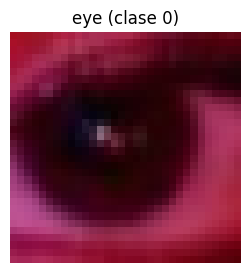

In [ ]:
display_img(train_set, 1515)


## 5. Dividir en entrenamiento / validación y crear los *DataLoaders*

Separamos una parte para **validación** y envolvemos los `DataLoader` con
`DeviceDataLoader` para que cada batch llegue directo a la GPU.


In [ ]:
batch_size = 40
val_size   = 960
train_size = len(train_set) - val_size

train_data, val_data = random_split(train_set, [train_size, val_size])
print(f"Tamano Train      : {len(train_data)}")
print(f"Tamano Validacion : {len(val_data)}")

# DataLoaders (num_workers=2 para evitar el warning de Colab)
train_dl = DataLoader(train_data, batch_size, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_data,   batch_size*2,               num_workers=2, pin_memory=True)

# envolver para que los batches vayan al dispositivo (GPU/CPU)
train_dl = DeviceDataLoader(train_dl, device)
val_dl   = DeviceDataLoader(val_dl,   device)


Tamano Train      : 5614
Tamano Validacion : 960


## 6. Visualizar un batch completo

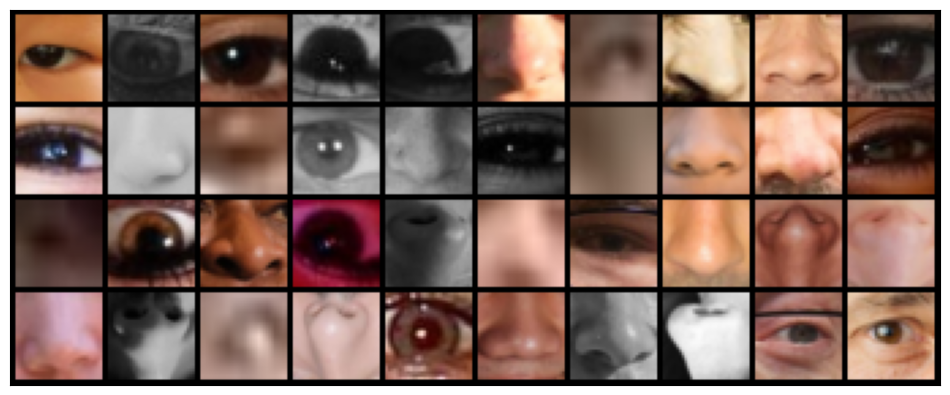

In [ ]:
show_batch(train_dl, nrow=10)


## 7. ¿Qué es `ImageClassificationBase`?

Es la **clase base** que definimos en la sección 3.2. Hereda de `nn.Module` y
agrupa la lógica de entrenamiento común a cualquier clasificador de imágenes:

- `training_step` → calcula la pérdida (*loss*) de un batch durante el entrenamiento.
- `validation_step` → calcula pérdida y *accuracy* de un batch de validación.
- `validation_epoch_end` → promedia los resultados de todos los batches de la época.
- `epoch_end` → imprime el resumen de cada época.

Tu red `CNN_Classification` **hereda** de esta clase, así que solo necesitas definir
las **capas** (en `__init__`) y el `forward`. Toda la "maquinaria" de entrenamiento
ya viene incluida. Es el mismo patrón del curso (estilo *Jovian / fast.ai*).


## 8. Definir la arquitectura de la CNN

Esta es una versión limpia y estándar (3 bloques de convolución + clasificador).
La arquitectura original tenía un `stride=6` poco habitual y un `Dropout` después
de la capa final; aquí lo dejamos en una forma más típica y fácil de explicar.
Cada comentario indica el tamaño del tensor a la salida de cada bloque.


In [ ]:
class CNN_Classification(ImageClassificationBase):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            # entrada: 3 x 32 x 32
            nn.Conv2d(3, 16, kernel_size=3, padding=1),   # -> 16 x 32 x 32
            nn.ReLU(),
            nn.MaxPool2d(2, 2),                           # -> 16 x 16 x 16

            nn.Conv2d(16, 32, kernel_size=3, padding=1),  # -> 32 x 16 x 16
            nn.ReLU(),
            nn.MaxPool2d(2, 2),                           # -> 32 x 8 x 8

            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # -> 64 x 8 x 8
            nn.ReLU(),
            nn.MaxPool2d(2, 2),                           # -> 64 x 4 x 4

            nn.Flatten(),                                 # -> 1024
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 2)                             # -> 2 clases (eye, nose)
        )

    def forward(self, xb):
        return self.network(xb)


## 9. Ver la arquitectura de la red

`print(model)` muestra las capas, pero **no** las dimensiones de salida (por eso
antes "solo se veían las líneas de arriba"). Para un resumen completo —forma de
salida y número de parámetros por capa— usamos `torchinfo`, que sí recorre **toda**
la red con un tensor de prueba.


In [ ]:
# crear el modelo y moverlo a la GPU/CPU
model = to_device(CNN_Classification(), device)
print(model)


CNN_Classification(
  (network): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Flatten(start_dim=1, end_dim=-1)
    (10): Linear(in_features=1024, out_features=128, bias=True)
    (11): ReLU()
    (12): Dropout(p=0.25, inplace=False)
    (13): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [ ]:
!pip install torchinfo -q
from torchinfo import summary

# input_size = (batch, canales, alto, ancho)
summary(model, input_size=(1, 3, 32, 32))


Layer (type:depth-idx)                   Output Shape              Param #
CNN_Classification                       [1, 2]                    --
├─Sequential: 1-1                        [1, 2]                    --
│    └─Conv2d: 2-1                       [1, 16, 32, 32]           448
│    └─ReLU: 2-2                         [1, 16, 32, 32]           --
│    └─MaxPool2d: 2-3                    [1, 16, 16, 16]           --
│    └─Conv2d: 2-4                       [1, 32, 16, 16]           4,640
│    └─ReLU: 2-5                         [1, 32, 16, 16]           --
│    └─MaxPool2d: 2-6                    [1, 32, 8, 8]             --
│    └─Conv2d: 2-7                       [1, 64, 8, 8]             18,496
│    └─ReLU: 2-8                         [1, 64, 8, 8]             --
│    └─MaxPool2d: 2-9                    [1, 64, 4, 4]             --
│    └─Flatten: 2-10                     [1, 1024]                 --
│    └─Linear: 2-11                      [1, 128]                  131,200
│ 

## 10. Entrenar el modelo

`fit` entrena y **guarda automáticamente el mejor modelo** (según `val_acc`) en
`best_model.pt`. Puedes ajustar `num_epochs` y `lr` libremente; con `Adam` y
`lr=0.001` esta tarea converge rápido.


In [ ]:
num_epochs = 25
opt_func   = torch.optim.Adam
lr         = 0.001

history = fit(num_epochs, lr, model, train_dl, val_dl, opt_func)


Epoca [ 0]  train_loss: 0.1505  val_loss: 0.0255  val_acc: 0.9917
Epoca [ 1]  train_loss: 0.0413  val_loss: 0.0351  val_acc: 0.9896
Epoca [ 2]  train_loss: 0.0329  val_loss: 0.0183  val_acc: 0.9938
Epoca [ 3]  train_loss: 0.0307  val_loss: 0.0194  val_acc: 0.9948
Epoca [ 4]  train_loss: 0.0288  val_loss: 0.0161  val_acc: 0.9958
Epoca [ 5]  train_loss: 0.0228  val_loss: 0.0286  val_acc: 0.9865
Epoca [ 6]  train_loss: 0.0244  val_loss: 0.0153  val_acc: 0.9958
Epoca [ 7]  train_loss: 0.0255  val_loss: 0.0148  val_acc: 0.9969
Epoca [ 8]  train_loss: 0.0185  val_loss: 0.0184  val_acc: 0.9948
Epoca [ 9]  train_loss: 0.0165  val_loss: 0.0242  val_acc: 0.9906
Epoca [10]  train_loss: 0.0194  val_loss: 0.0199  val_acc: 0.9948
Epoca [11]  train_loss: 0.0132  val_loss: 0.0165  val_acc: 0.9969
Epoca [12]  train_loss: 0.0120  val_loss: 0.0187  val_acc: 0.9948
Epoca [13]  train_loss: 0.0126  val_loss: 0.0206  val_acc: 0.9969
Epoca [14]  train_loss: 0.0094  val_loss: 0.0188  val_acc: 0.9969
Epoca [15]

## 11. Curvas de *accuracy* y *loss*

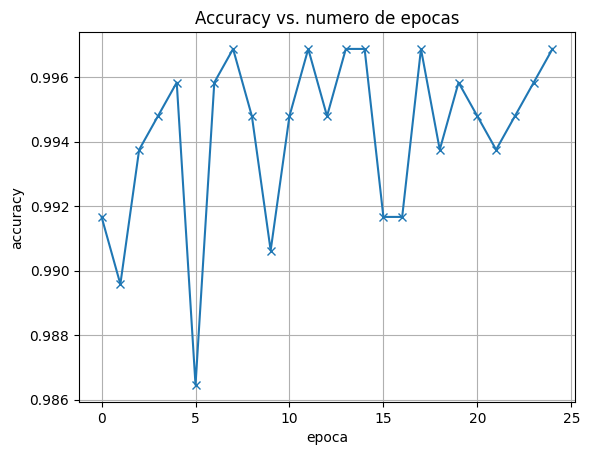

In [ ]:
plot_accuracies(history)


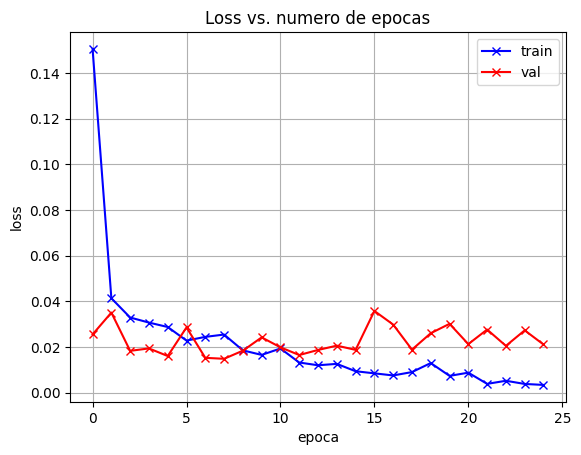

In [ ]:
plot_losses(history)


## 12. Cargar el mejor modelo y evaluar en *test*

In [ ]:
model = load_model(CNN_Classification, 'best_model.pt')


Modelo cargado desde 'best_model.pt'


In [ ]:
ytest = get_labels(model, test_set)
ypred = get_prediction(model, test_set)

acc = accuracy_score(ytest, ypred)
C   = confusion_matrix(ytest, ypred)

print('Desempeno en el subconjunto de Test:')
print('Accuracy:', round(acc, 4))
print(' ')
print('Matriz de confusion =')
print(C)


Desempeno en el subconjunto de Test:
Accuracy: 1.0
 
Matriz de confusion =
[[74  0]
 [ 0 74]]


Matriz de confusion =
[[74  0]
 [ 0 74]]

Accuracy = 1.0000


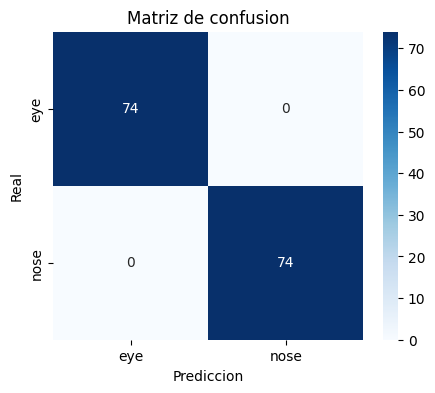

array([[74,  0],
       [ 0, 74]])

In [ ]:
print_confusion(ytest, ypred, classes=test_set.classes, show_heatmap=1)


### Desempeño en los tres subconjuntos

In [ ]:
C1, acc1 = performance(model, train_data, 'Training')
C2, acc2 = performance(model, val_data,   'Validation')
C3, acc3 = performance(model, test_set,   'Testing')


Training Confusion Matrix = 
[[2813   17]
 [   8 2776]]
 
Training Accuracy = 0.9955
 
Validation Confusion Matrix = 
[[456   1]
 [  2 501]]
 
Validation Accuracy = 0.9969
 
Testing Confusion Matrix = 
[[74  0]
 [ 0 74]]
 
Testing Accuracy = 1.0000
 


---
*Cuaderno adaptado para el módulo de Visión por Computador del diplomado de inteligencia artificial aplicada a la industria tecnológica · Universidad de Santiago de Chile.*
---
<a href="https://example.com">04_buscar_cara.ipynb</a> © 2026 by <a href="https://example.com">Diego Fischer</a> is licensed under <a href="https://creativecommons.org/licenses/by/4.0/">CC BY 4.0</a><img src="https://mirrors.creativecommons.org/presskit/icons/cc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/by.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;">